# TLM Score Eval -- Thesis Score Tables + Plots (Colab)

Minimal, reusable eval notebook: runs the full greedy-decode eval over a
held-out split for one checkpoint and produces exactly two things a thesis
figure/table needs -- the headline scorecard (mean score / applied_ok% per
task, plus the bar chart) and the complexity-stratified score table. No
calibration analysis, no qualitative example dumps, no ladder-comparison
table, no confidence tracking during decode -- just the headline scorecard and
the complexity-stratified table, so XS/S/M can be re-scored under the current
`src/eval/scorers.py` without extra machinery (XXS is listed in `MODEL_VARIANT` but
intentionally raises -- no verified XXS config exists in this repo yet, see
Cell 2's comment).

Set `MODEL_VARIANT` + `RUN_NAME` + `CKPT_NAME` in Cell 2, run top to bottom.
Defaults to the TLM-M pre-RL SFT checkpoint (`tlm_m_sft_epoch_24_val0.1815.pt`)
so the first run of this notebook produces the fixed-scorer baseline needed
before the next RL-on-M run.

## Clean run -- what to change

This notebook **resumes from disk**. Every task type's greedy-decode results are
cached to `<CKPT_DIR>/score_eval_outputs/eval_cache/*.pkl` (and the smoke-test /
gold-check cells cache `*_smoke.pkl` in the same folder). On a re-run those files
are reloaded instead of being recomputed, so a committed cache reproduces the
saved tables without touching a GPU. To reproduce the numbers *from scratch*:

1. **Environment.** Run on Linux (Colab, WSL, or a Linux host). The execution-based
   smoke-test cell and the gold-self-consistency cell call `mp.get_context("fork")`,
   which only exists on Linux/macOS -- on native Windows they raise
   `ValueError: cannot find context for 'fork'`. The rest of the notebook is
   platform-independent. GPU strongly recommended (~3750 greedy decodes).
2. **Checkpoint identity.** Set `MODEL_VARIANT`, `RUN_NAME`, `CKPT_NAME` in the
   "Run Config + Checkpoint" cell. These three lines are the only per-run change;
   every path below is derived from them.
3. **Paths.** Colab original: `DRIVE_ROOT = /content/drive/MyDrive/TLM_V03` -- edit
   if your Drive layout differs. Local copy: paths come from `_localenv.py`
   (set the `TLM_DATA` env var to move the data root); no edit needed.
4. **Force recompute.** Delete the cache first, or the run just reloads the old
   results:
   `rm -rf <DATA_ROOT>/checkpoints/<RUN_NAME>/score_eval_outputs/eval_cache/`
   (equivalently, pass `resume=False` to `run_score_eval(...)`).
5. **Data.** `data/finetune_data/sft_val_domain.jsonl` (held-out SFT split) and the
   `.pt` checkpoint named by `CKPT_NAME` must be present.


## 1 -- Setup

In [1]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

import sys, os, re, json, math, time, pickle
from pathlib import Path
from collections import defaultdict

DRIVE_ROOT = Path('/content/drive/MyDrive/TLM_V03')
assert DRIVE_ROOT.exists(), f"{DRIVE_ROOT} not found -- upload the project to Drive first"
sys.path.insert(0, str(DRIVE_ROOT))

from src.model_config import ModelConfig, count_parameters
from src.model_variants import TLM_S
from src.tokenizer import TLM_Tokenizer
from src.data_set import make_sft_sr, apply_sr, split_lines_by_newline, join_lines
from src.data_loaders import SFTDataset, collate_sft
from src.training import validate
from src.inference import greedy_decode, decode_rename_without_collision
from src.eval.smoke_test import SMOKE_TEST_SCORERS
from collections import Counter


import torch
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}  |  PyTorch: {torch.__version__}")

Mounted at /content/drive
[tlm_s.py] Loaded TLM_S model variant
[training.py] SRC_VERSION = role-aware-pgen-v4-intuitive-last
[calibration_training.py] SRC_VERSION = calibration-selfrollout-v2-batched
[confidence_head_training.py] SRC_VERSION = confidence-head-v1
Device: cpu  |  PyTorch: 2.11.0+cpu


## 2 -- Run Config + Checkpoint

Only the four lines below change between runs. `CKPT_NAME` picks the exact
checkpoint file directly (no auto-"lowest val loss" guessing, no RL/
calibration schema branching) -- keeps this notebook simple and the checkpoint
choice explicit and auditable in the saved output.

In [2]:
MODEL_VARIANT = "M"   # "XS" | "S" | "M"  ("XXS" intentionally unimplemented, see branch below)
RUN_NAME      = "tlm_m_sft_unbiased_copy"
CKPT_NAME     = "tlm_m_sft_unbiased_copy_epoch_25_val0.1605.pt"

if MODEL_VARIANT == "XXS":
    config = ModelConfig(d_model=96, d_ff=384, n_encoder_layers=3, n_decoder_layers=3,
                             n_heads=3, tier_name="TLM_XXS", target_param_count=1_740_000)
elif MODEL_VARIANT == "XS":
    config = ModelConfig(d_model=128, d_ff=512, tier_name="TLM_XS", target_param_count=2_420_000)
elif MODEL_VARIANT == "S":
    config = ModelConfig()
else:  # "M" -- 256 d_model / 1024 d_ff, same 4+4 layers / 4 heads / 6 task types as S
    config = ModelConfig(d_model=256, d_ff=1024, tier_name="TLM_M", target_param_count=9_500_000)
print(config)


tlm_s  = TLM_S(config)  # class is architecture-agnostic -- entirely parameterized by `config`
PAD_ID = config.special_token_ids["pad"]

TOKENIZER_PATH = str(DRIVE_ROOT / "src" / "tokenizer" / "tokenizer_tlm_small.json")
EVAL_PATH      = DRIVE_ROOT / "data" / "finetune_data" / "sft_val_domain.jsonl"
SFT_CKPT_DIR   = DRIVE_ROOT / "data" / "checkpoints" / RUN_NAME
CKPT_PATH      = SFT_CKPT_DIR / CKPT_NAME

OUTPUT_DIR     = SFT_CKPT_DIR / "score_eval_outputs"
EVAL_CACHE_DIR = OUTPUT_DIR / "eval_cache"
FIGURES_DIR    = OUTPUT_DIR / "figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
EVAL_CACHE_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

assert CKPT_PATH.exists(), f"Checkpoint not found: {CKPT_PATH}"
assert EVAL_PATH.exists(), f"Eval data not found: {EVAL_PATH}"

state = torch.load(CKPT_PATH, map_location=device)
tlm_s.load_state_dict(state["model"])
tlm_s.to(device).eval()

print(f"MODEL_VARIANT: {MODEL_VARIANT}  |  checkpoint: {CKPT_NAME}")
print(f"epoch        : {state['epoch']}")
print(f"model params : {count_parameters(tlm_s)/1e6:.3f}M")
print(f"outputs -> {OUTPUT_DIR}")

[Config] Estimated params: embed=2560000, enc_attn=1048576, dec_attn=2097152, enc_ffn=2102272, dec_ffn=2102272, enc_ln=4608, dec_ln=6656, task_emb=6144, copy_head=257, head=0
ModelConfig [TLM_M]
  d_model=256, n_heads=4
  Encoder: 4L  Decoder: 4L  FFN: 1024
  Estimated: 9.93M params  (target: 9.50M)
  Vocab: 10000  MaxSeq: 1024  TaskTypes: 6  WeightTie: True
[tlm_s.py] Initialized TLM_S model variant with 9927937 parameters
MODEL_VARIANT: M  |  checkpoint: tlm_m_sft_unbiased_copy_epoch_25_val0.1605.pt
epoch        : 25
model params : 9.928M
outputs -> /content/drive/MyDrive/TLM_V03/data/checkpoints/tlm_m_sft_unbiased_copy/score_eval_outputs


## 3 -- Tokenizer + Eval Data

In [3]:
tokenizer = TLM_Tokenizer(vocab_size=config.vocab_size)
tokenizer.load(TOKENIZER_PATH)

by_type = defaultdict(list)
with open(EVAL_PATH, encoding="utf-8") as f:
    for line in f:
        d = json.loads(line)
        by_type[d["type"]].append(d)

print(f"eval records per type (EVAL_PATH = {EVAL_PATH.name}):")
for t, recs in by_type.items():
    print(f"  {t:20s}: {len(recs)}")
print(f"  total              : {sum(len(v) for v in by_type.values())}")

_NL = config.special_token_ids["newline"]
_BOS = config.special_token_ids["bos"]
_EOS = config.special_token_ids["eos"]

eval records per type (EVAL_PATH = sft_val_domain.jsonl):
  remove_dead_code    : 750
  rename              : 750
  simplify            : 750
  extract_method      : 750
  deduplicate         : 750
  total              : 3750


## 4 -- Scorers (canonical, from `src/eval/scorers.py`)

Imported directly from `src/eval/scorers.py`, never an inline copy -- this is
the same rubric `src/training/rl_training.py` uses as its reward function, so
any score produced here is directly comparable to an RL run's reported
reward.

In [4]:
from src.eval.scorers import TASK_SCORERS

TASK_ORDER = ["rename", "simplify", "deduplicate", "remove_dead_code", "extract_method"]

print("TASK_SCORERS:", {k: v.__name__ for k, v in TASK_SCORERS.items()})

# applied_ok's per-sample cutoff (is_ok = score >= threshold). rename/remove_dead_code's
# scores are recall/consistency/precision products over discrete sites/lines -- many
# different genuinely-correct outputs land exactly at 1.0, so >=0.999 is a meaningful
# "fully correct" bar there. simplify/deduplicate/extract_method's scores are built from
# SequenceMatcher ratios and continuous AST-based proxies that essentially never land at
# exact 1.0 unless pred is byte-identical to gold -- 0.85 keeps applied_ok informative as a
# stricter secondary signal instead of a near-exact-match one; mean_score stays primary.
OK_SCORE_THRESHOLD = {
    "rename": 0.999,
    "remove_dead_code": 0.999,
    "simplify": 0.85,
    "deduplicate": 0.85,
    "extract_method": 0.85,
}

def _bucket_label_discrete(v, cap):
    if v is None:
        return "n/a"
    return str(v) if v < cap else f"{cap}+"

def _bucket_label_quantile(v, all_vals, n_buckets=3, labels=("short", "medium", "long")):
    if v is None or not all_vals:
        return "n/a"
    sorted_vals = sorted(all_vals)
    edges = [sorted_vals[int(len(sorted_vals) * i / n_buckets)] for i in range(1, n_buckets)]
    idx = sum(1 for e in edges if v > e)
    return labels[min(idx, len(labels) - 1)]

COMPLEXITY_BUCKETS = {
    "rename":           (lambda v, allv: _bucket_label_discrete(v, 4), ["1", "2", "3", "4+", "n/a"]),
    "remove_dead_code": (lambda v, allv: _bucket_label_discrete(v, 3), ["1", "2", "3+", "n/a"]),
    "simplify":         (lambda v, allv: _bucket_label_discrete(v, 3), ["1", "2", "3+", "n/a"]),
    "deduplicate":      (lambda v, allv: _bucket_label_discrete(v, 3), ["1", "2", "3+", "n/a"]),
    "extract_method":   (lambda v, allv: _bucket_label_quantile(v, allv), ["short", "medium", "long", "n/a"]),
}

TASK_SCORERS: {'rename': 'score_rename', 'extract_method': 'score_extract_method', 'simplify': 'score_simplify', 'deduplicate': 'score_deduplicate', 'remove_dead_code': 'score_remove_dead_code'}


## 5 -- Full Eval Run (greedy decode, every held-out record)

Cached per task type to disk (`EVAL_CACHE_DIR`) -- re-running this cell after
a dropped session or kernel restart resumes instead of redecoding from
scratch. No confidence/calibration tracking here (`collect_conf=False`) --
this notebook only needs `score`/`complexity` per sample.

In [5]:
PROGRESS_EVERY = 25

def _ttype_cache_path(cache_dir, ttype):
    return cache_dir / f"{ttype}_score_eval.pkl"

def run_score_eval(by_type_dict, model, progress_every=PROGRESS_EVERY, cache_dir=EVAL_CACHE_DIR, resume=True):
    results = {}
    t0 = time.perf_counter()
    n_done = 0
    n_total = sum(len(recs) for recs in by_type_dict.values())

    for ttype, recs in by_type_dict.items():
        cache_path = _ttype_cache_path(cache_dir, ttype)
        if resume and cache_path.exists():
            with open(cache_path, "rb") as f:
                results[ttype] = pickle.load(f)
            n_done += len(recs)
            r = results[ttype]
            print(f"--- [{ttype}] loaded from cache: {r['ok']}/{r['total']} ok, "
                  f"mean_score={sum(r['scores'])/max(len(r['scores']),1):.3f} ---", flush=True)
            continue

        print(f"\n--- [{ttype}] starting, {len(recs)} samples ---", flush=True)
        ok = trunc = parse_fail = total = 0
        scores, complexities = [], []
        for i, d in enumerate(recs):
            res = make_sft_sr(d, tokenizer, config)
            if res is None:
                continue
            enc_ids, _, task_id = res
            before_ids = tokenizer.encode(d["before"])
            after_ids  = tokenizer.encode(d["after"])
            gold_after = join_lines(split_lines_by_newline(after_ids, _NL), _NL)

            if ttype == "rename":
                out = decode_rename_without_collision(model, enc_ids, task_id, device, before_ids,
                                                      tokenizer, config, max_retries=2, collect_conf=False)
            else:
                out = greedy_decode(model, enc_ids, task_id, device, collect_conf=False)
            pred_dec = out["tokens"]
            pred_after = apply_sr(before_ids, pred_dec, config)

            total += 1
            if pred_dec[-1] != _EOS:
                trunc += 1
            if pred_after is None:
                parse_fail += 1

            before_text = tokenizer.decode(before_ids)
            pred_text = tokenizer.decode(pred_after) if pred_after is not None else None
            gold_text = tokenizer.decode(gold_after)
            score_result = TASK_SCORERS[ttype](before_text, pred_text, gold_text)
            sample_score = score_result["score"]
            is_ok = sample_score >= OK_SCORE_THRESHOLD.get(ttype, 0.999)

            scores.append(sample_score)
            complexities.append(score_result.get("complexity"))
            if is_ok:
                ok += 1
            n_done += 1
            if (i + 1) % progress_every == 0 or (i + 1) == len(recs):
                elapsed = time.perf_counter() - t0
                eta = (n_total - n_done) / max(n_done / max(elapsed, 1e-9), 1e-9)
                print(f"  [{ttype}] {i+1}/{len(recs)}  ok so far: {ok}  "
                      f"| overall {n_done}/{n_total}  elapsed {elapsed:.0f}s  ETA {eta:.0f}s", flush=True)

        results[ttype] = {"ok": ok, "total": total, "trunc": trunc, "parse_fail": parse_fail,
                          "scores": scores, "complexities": complexities}
        with open(cache_path, "wb") as f:
            pickle.dump(results[ttype], f)
        mean_score = sum(scores) / max(len(scores), 1)
        print(f"{ttype:20s}: {ok:3d}/{total:<3d} ({ok/max(total,1)*100:5.1f}%)  mean_score={mean_score:.3f}  "
              f"trunc={trunc}  parse_fail={parse_fail}  [cached -> {cache_path.name}]")

    elapsed = time.perf_counter() - t0
    total_ok  = sum(v["ok"]    for v in results.values())
    total_tot = sum(v["total"] for v in results.values())
    print(f"\n{'OVERALL':20s}: {total_ok:3d}/{total_tot:<3d} ({total_ok/max(total_tot,1)*100:5.1f}%)  "
          f"elapsed {elapsed:.0f}s")
    return results, total_ok, total_tot


results, total_ok, total_tot = run_score_eval(by_type, tlm_s)

--- [remove_dead_code] loaded from cache: 573/750 ok, mean_score=0.873 ---
--- [rename] loaded from cache: 313/750 ok, mean_score=0.636 ---
--- [simplify] loaded from cache: 281/750 ok, mean_score=0.530 ---
--- [extract_method] loaded from cache: 166/750 ok, mean_score=0.426 ---
--- [deduplicate] loaded from cache: 161/747 ok, mean_score=0.442 ---

OVERALL             : 1494/3747 ( 39.9%)  elapsed 4s


## Execution-based smoke test (opt-in, src/eval/smoke_test.py)

In [6]:
# -- Cell: Execution-based smoke test (opt-in, src/eval/smoke_test.py) -------
# Same structure/cache/resume logic as before -- only the smoke-scorer call
# itself now goes through a recycled worker process (maxtasksperchild=20)
# instead of running in-process. See smoke_test_pool_worker's docstring for
# why: confirmed empirically (rename/simplify both completed cleanly at
# 750/750, then deduplicate died ~175 in) that this is cumulative thread
# accumulation across the whole session, not a per-task bug -- recycling the
# worker process every 20 samples reaps every thread it ever spawned, hung
# or not, before it can pile up.
from src.eval.smoke_test import SMOKE_TEST_SCORERS, smoke_test_pool_worker
from collections import Counter
import random as _random
import multiprocessing as mp

SMOKE_TEST_TIMEOUT_S = 2.0
SMOKE_TEST_TYPES = ["rename", "simplify", "deduplicate", "extract_method"]
SMOKE_TEST_SAMPLE_SIZE = 750
SMOKE_TEST_CHECKPOINT_EVERY = 25
SMOKE_POOL_MAXTASKSPERCHILD = 20
_smoke_rng = _random.Random(0)

def _smoke_cache_path(cache_dir, ttype):
    return cache_dir / f"{ttype}_smoke.pkl"

smoke_results = []
for ttype in SMOKE_TEST_TYPES:
    scorer = SMOKE_TEST_SCORERS.get(ttype)
    if scorer is None:
        continue
    cache_path = _smoke_cache_path(EVAL_CACHE_DIR, ttype)
    recs_all = by_type[ttype]
    sample_recs = recs_all if len(recs_all) <= SMOKE_TEST_SAMPLE_SIZE else \
        _smoke_rng.sample(recs_all, SMOKE_TEST_SAMPLE_SIZE)

    if cache_path.exists():
        with open(cache_path, "rb") as f:
            type_results = pickle.load(f)
        print(f"--- [{ttype}] resuming: {len(type_results)}/{len(sample_recs)} already done ---")
    else:
        type_results = []

    start_idx = len(type_results)
    if start_idx < len(sample_recs):
        print(f"\n--- [{ttype}] smoke-testing {len(sample_recs)} samples via pool "
              f"(resuming from {start_idx}, maxtasksperchild={SMOKE_POOL_MAXTASKSPERCHILD}) ---", flush=True)

        ctx = mp.get_context("fork")  # Colab is Linux -- fork avoids the Windows spawn/__main__ dance
        with ctx.Pool(processes=1, maxtasksperchild=SMOKE_POOL_MAXTASKSPERCHILD) as pool:
            for i in range(start_idx, len(sample_recs)):
                d = sample_recs[i]
                res = make_sft_sr(d, tokenizer, config)
                if res is None:
                    type_results.append({"ttype": ttype, "smoke_ok": None, "reason": "encode_fail",
                                          "scorer_score": None, "scorer_ok": None})
                    continue
                enc_ids, _, task_id = res
                before_ids = tokenizer.encode(d["before"])
                after_ids  = tokenizer.encode(d["after"])
                gold_after = join_lines(split_lines_by_newline(after_ids, _NL), _NL)

                if ttype == "rename":
                    out = decode_rename_without_collision(tlm_s, enc_ids, task_id, device, before_ids,
                                                           tokenizer, config, max_retries=2, collect_conf=False)
                else:
                    out = greedy_decode(tlm_s, enc_ids, task_id, device, collect_conf=False)
                pred_after = apply_sr(before_ids, out["tokens"], config)

                before_text = tokenizer.decode(before_ids)
                pred_text = tokenizer.decode(pred_after) if pred_after is not None else None
                gold_text = tokenizer.decode(gold_after)

                ast_result = TASK_SCORERS[ttype](before_text, pred_text, gold_text)
                scorer_ok = ast_result["score"] >= OK_SCORE_THRESHOLD.get(ttype, 0.999)

                r = pool.apply(smoke_test_pool_worker,
                               ((ttype, before_text, pred_text, gold_text, SMOKE_TEST_TIMEOUT_S),))

                type_results.append({"ttype": ttype, "scorer_score": ast_result["score"],
                                      "scorer_ok": scorer_ok, **r})

                if (i + 1) % SMOKE_TEST_CHECKPOINT_EVERY == 0 or (i + 1) == len(sample_recs):
                    with open(cache_path, "wb") as f:
                        pickle.dump(type_results, f)
                    print(f"  [{ttype}] {i+1}/{len(sample_recs)}  [checkpointed]", flush=True)

    smoke_results.extend(type_results)

print(f"\n{len(smoke_results)} samples run through the smoke test "
      f"({', '.join(SMOKE_TEST_TYPES)} only, {SMOKE_TEST_SAMPLE_SIZE}/task)\n")
for ttype in SMOKE_TEST_TYPES:
    subset = [r for r in smoke_results if r["ttype"] == ttype]
    if not subset:
        continue
    counts = Counter(r["smoke_ok"] for r in subset)
    n = len(subset)
    print(f"{ttype:16s}: n={n}  smoke_ok=True {counts.get(True, 0)}/{n}  "
          f"smoke_ok=False {counts.get(False, 0)}/{n}  inconclusive(None) {counts.get(None, 0)}/{n}")

with open(OUTPUT_DIR / "smoke_test_results.json", "w", encoding="utf-8") as f:
    json.dump(smoke_results, f, indent=2, default=str)
print(f"\nSaved -> {OUTPUT_DIR / 'smoke_test_results.json'}")

--- [rename] resuming: 750/750 already done ---
--- [simplify] resuming: 750/750 already done ---
--- [deduplicate] resuming: 750/750 already done ---
--- [extract_method] resuming: 750/750 already done ---

3000 samples run through the smoke test (rename, simplify, deduplicate, extract_method only, 750/task)

rename          : n=750  smoke_ok=True 351/750  smoke_ok=False 96/750  inconclusive(None) 303/750
simplify        : n=750  smoke_ok=True 337/750  smoke_ok=False 146/750  inconclusive(None) 267/750
deduplicate     : n=750  smoke_ok=True 254/750  smoke_ok=False 149/750  inconclusive(None) 347/750
extract_method  : n=750  smoke_ok=True 237/750  smoke_ok=False 200/750  inconclusive(None) 313/750

Saved -> /content/drive/MyDrive/TLM_V03/data/checkpoints/tlm_m_sft_unbiased_copy/score_eval_outputs/smoke_test_results.json


## Scorer vs. Smoke Test: Where They Agree / Disagree

Side-by-side comparison for the three smoke-testable tasks. Each conclusive
sample (`smoke_ok` is `True`/`False`, i.e. execution didn't fail on the
gold/before baseline) falls into exactly one of four buckets:

- **both agree ok** -- AST scorer says `applied_ok`, execution didn't crash/
  mistype
- **both agree not ok** -- both say it's wrong
- **scorer ok, smoke not** -- AST scorer missed a real crash/type-mismatch bug
  (the scorer's blind spot)
- **smoke ok, scorer not** -- AST scorer is stricter than execution alone
  catches (could be a real bug the smoke test's fixed dummy input doesn't
  trigger, or the scorer being too strict)

Inconclusive samples (`smoke_ok is None`, gold/before baseline itself failed
to execute) are reported separately, not folded into the agreement rate.


task                 n  conclusive  inconclusive  |           both agree ok       both agree not ok    scorer ok, smoke not    smoke ok, scorer not
rename             750         447           303  |                     207                      75                      21                     144
simplify           750         483           267  |                     188                     131                      15                     149
deduplicate        750         403           347  |                     115                     139                      10                     139
extract_method     750         437           313  |                     117                     187                      13                     120


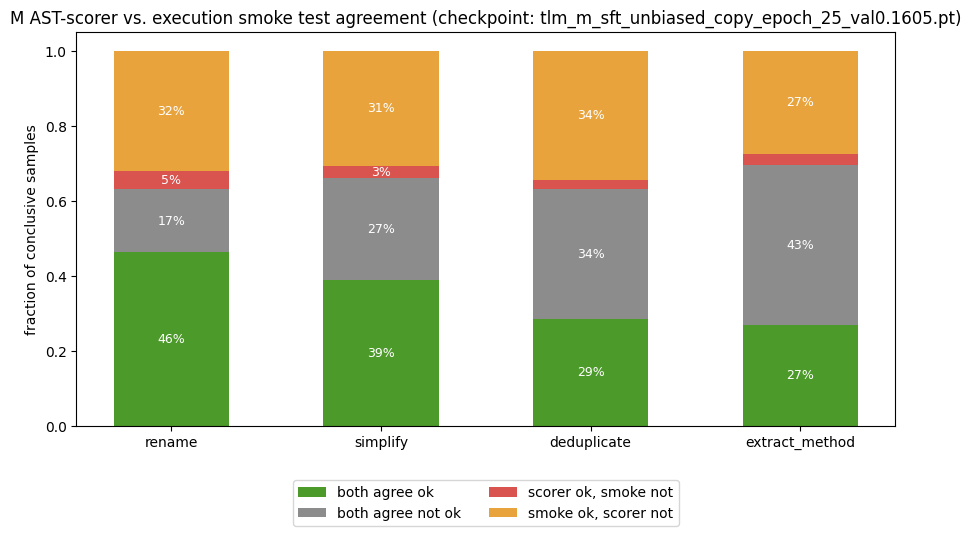

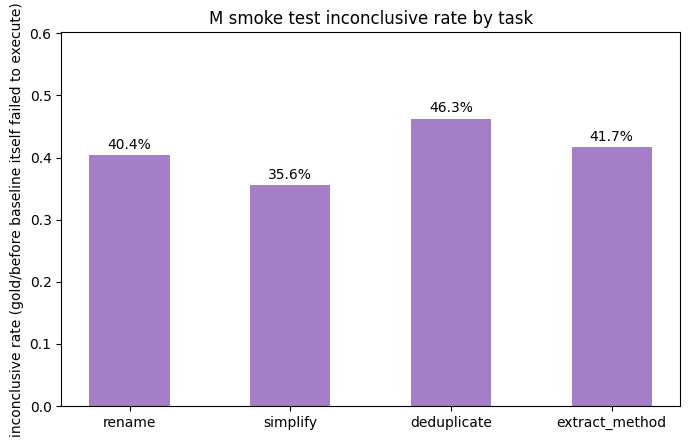


Saved -> /content/drive/MyDrive/TLM_V03/data/checkpoints/tlm_m_sft_unbiased_copy/score_eval_outputs/scorer_smoke_agreement.json


In [7]:
AGREEMENT_CATEGORIES = ["agree_ok", "agree_not_ok", "scorer_ok_smoke_not", "smoke_ok_scorer_not"]
AGREEMENT_LABELS = {
    "agree_ok": "both agree ok",
    "agree_not_ok": "both agree not ok",
    "scorer_ok_smoke_not": "scorer ok, smoke not",
    "smoke_ok_scorer_not": "smoke ok, scorer not",
}
AGREEMENT_COLORS = {
    "agree_ok": "#4C9A2A", "agree_not_ok": "#8C8C8C",
    "scorer_ok_smoke_not": "#D9534F", "smoke_ok_scorer_not": "#E8A33D",
}

def _categorize(r):
    if r["smoke_ok"] is None:
        return None  # inconclusive, handled separately
    if r["scorer_ok"] and r["smoke_ok"]:
        return "agree_ok"
    if not r["scorer_ok"] and not r["smoke_ok"]:
        return "agree_not_ok"
    if r["scorer_ok"] and not r["smoke_ok"]:
        return "scorer_ok_smoke_not"
    return "smoke_ok_scorer_not"

per_task_counts = {}
per_task_inconclusive = {}
for ttype in SMOKE_TEST_TYPES:
    subset = [r for r in smoke_results if r["ttype"] == ttype]
    n = len(subset)
    n_inconclusive = sum(1 for r in subset if r["smoke_ok"] is None)
    conclusive = [r for r in subset if r["smoke_ok"] is not None]
    n_conclusive = len(conclusive)
    cat_counts = Counter(_categorize(r) for r in conclusive)
    per_task_counts[ttype] = {c: cat_counts.get(c, 0) for c in AGREEMENT_CATEGORIES}
    per_task_inconclusive[ttype] = {"n": n, "n_conclusive": n_conclusive, "n_inconclusive": n_inconclusive}

print(f"{'task':16s} {'n':>5} {'conclusive':>11} {'inconclusive':>13}  |  " +
      "  ".join(f"{AGREEMENT_LABELS[c]:>22s}" for c in AGREEMENT_CATEGORIES))
for ttype in SMOKE_TEST_TYPES:
    info = per_task_inconclusive[ttype]
    counts = per_task_counts[ttype]
    print(f"{ttype:16s} {info['n']:5d} {info['n_conclusive']:11d} {info['n_inconclusive']:13d}  |  " +
          "  ".join(f"{counts[c]:22d}" for c in AGREEMENT_CATEGORIES))

# -- Plot 1: per-task stacked bar of agreement categories (fraction of conclusive samples) --
fig, ax = plt.subplots(figsize=(9, 5.5))
x = range(len(SMOKE_TEST_TYPES))
bottoms = [0.0] * len(SMOKE_TEST_TYPES)
for cat in AGREEMENT_CATEGORIES:
    fracs = [per_task_counts[t][cat] / max(per_task_inconclusive[t]["n_conclusive"], 1) for t in SMOKE_TEST_TYPES]
    ax.bar(x, fracs, bottom=bottoms, label=AGREEMENT_LABELS[cat], color=AGREEMENT_COLORS[cat], width=0.55)
    for xi, (frac, bot) in enumerate(zip(fracs, bottoms)):
        if frac > 0.03:
            ax.text(xi, bot + frac / 2, f"{frac:.0%}", ha="center", va="center", fontsize=9, color="white")
    bottoms = [b + f for b, f in zip(bottoms, fracs)]
ax.set_xticks(list(x)); ax.set_xticklabels(SMOKE_TEST_TYPES)
ax.set_ylabel("fraction of conclusive samples"); ax.set_ylim(0, 1.05)
ax.set_title(f"{MODEL_VARIANT} AST-scorer vs. execution smoke test agreement (checkpoint: {CKPT_NAME})")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "scorer_smoke_agreement.png", dpi=150, bbox_inches="tight")
plt.show()

# -- Plot 2: inconclusive rate per task (separate axis -- different meaning than the agreement fractions above) --
fig, ax = plt.subplots(figsize=(7, 4.5))
inconclusive_rates = [per_task_inconclusive[t]["n_inconclusive"] / max(per_task_inconclusive[t]["n"], 1) for t in SMOKE_TEST_TYPES]
bars = ax.bar(SMOKE_TEST_TYPES, inconclusive_rates, color="#9467BD", alpha=0.85, width=0.5)
for bar, val in zip(bars, inconclusive_rates):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.01, f"{val:.1%}", ha="center", fontsize=10)
ax.set_ylim(0, max(inconclusive_rates + [0.1]) * 1.3)
ax.set_ylabel("inconclusive rate (gold/before baseline itself failed to execute)")
ax.set_title(f"{MODEL_VARIANT} smoke test inconclusive rate by task")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "scorer_smoke_inconclusive_rate.png", dpi=150, bbox_inches="tight")
plt.show()

agreement_table = [
    {"task": t, **per_task_inconclusive[t], **{AGREEMENT_LABELS[c]: per_task_counts[t][c] for c in AGREEMENT_CATEGORIES}}
    for t in SMOKE_TEST_TYPES
]
with open(OUTPUT_DIR / "scorer_smoke_agreement.json", "w", encoding="utf-8") as f:
    json.dump(agreement_table, f, indent=2)
print(f"\nSaved -> {OUTPUT_DIR / 'scorer_smoke_agreement.json'}")

## Gold Self-Consistency ("Ceiling") Check

Runs both the AST scorer and the smoke test with `pred=gold` -- i.e. treats
gold as if it were the model's own prediction. This is the ceiling each
metric can actually reach, not 100%: even a verbatim `gold==pred` match
doesn't always hit `applied_ok` for `extract_method`/`deduplicate` (their
structural matcher only landed ~82-89% in a prior check). This cell measures
that ceiling directly on this run's actual held-out data for **every** task
the AST scorer covers (including `remove_dead_code`, which has no smoke
test), and for the smoke test on the 4 tasks it covers. A low gold-ceiling
number is a property of the metric's strictness, not evidence the model is
worse than it looks -- but it's necessary context for reading the headline
`applied_ok%` numbers honestly.

In [8]:
# -- Gold self-consistency check: score/smoke-test gold against itself (pred=gold) --
# Same before_text/gold_text normalization as the main eval loop (tokenizer
# encode->decode round-trip) so this is measured on the exact same text basis
# pred is scored against, not raw un-normalized jsonl strings. Smoke test still
# goes through the recycled pool (same accumulation risk as any other exec-heavy
# pass over hundreds of samples).
import multiprocessing as mp

GOLD_CHECK_TIMEOUT_S = 2.0
GOLD_CHECK_POOL_MAXTASKSPERCHILD = 20

gold_check = {}
for ttype in TASK_ORDER:
    recs = by_type[ttype]
    ast_ok = 0
    smoke_counts = {True: 0, False: 0, None: 0}
    has_smoke = SMOKE_TEST_SCORERS.get(ttype) is not None

    pool_cm = None
    if has_smoke:
        ctx = mp.get_context("fork")
        pool_cm = ctx.Pool(processes=1, maxtasksperchild=GOLD_CHECK_POOL_MAXTASKSPERCHILD)

    try:
        for i, d in enumerate(recs):
            before_ids = tokenizer.encode(d["before"])
            after_ids  = tokenizer.encode(d["after"])
            gold_after = join_lines(split_lines_by_newline(after_ids, _NL), _NL)
            before_text = tokenizer.decode(before_ids)
            gold_text = tokenizer.decode(gold_after)

            ast_result = TASK_SCORERS[ttype](before_text, gold_text, gold_text)
            if ast_result["score"] >= OK_SCORE_THRESHOLD.get(ttype, 0.999):
                ast_ok += 1

            if has_smoke:
                r = pool_cm.apply(smoke_test_pool_worker,
                                  ((ttype, before_text, gold_text, gold_text, GOLD_CHECK_TIMEOUT_S),))
                smoke_counts[r["smoke_ok"]] += 1

            if (i + 1) % 250 == 0:
                print(f"  [{ttype}] {i+1}/{len(recs)}", flush=True)
    finally:
        if pool_cm is not None:
            pool_cm.close(); pool_cm.join()

    entry = {"n": len(recs), "ast_gold_ok_pct": ast_ok / max(len(recs), 1) * 100}
    if has_smoke:
        n_smoke = sum(smoke_counts.values())
        entry.update({
            "smoke_gold_ok_pct": smoke_counts[True] / max(n_smoke, 1) * 100,
            "smoke_gold_not_ok_pct": smoke_counts[False] / max(n_smoke, 1) * 100,
            "smoke_gold_inconclusive_pct": smoke_counts[None] / max(n_smoke, 1) * 100,
        })
    gold_check[ttype] = entry
    print(f"{ttype:20s} done", flush=True)

print(f"\n{'task':20s} {'AST gold_ok%':>13}  {'smoke gold_ok%':>15}  {'smoke not_ok%':>14}  {'smoke inconcl%':>15}")
print("-" * 84)
for ttype in TASK_ORDER:
    r = gold_check[ttype]
    if "smoke_gold_ok_pct" in r:
        print(f"{ttype:20s} {r['ast_gold_ok_pct']:13.1f}  {r['smoke_gold_ok_pct']:15.1f}  "
              f"{r['smoke_gold_not_ok_pct']:14.1f}  {r['smoke_gold_inconclusive_pct']:15.1f}")
    else:
        print(f"{ttype:20s} {r['ast_gold_ok_pct']:13.1f}  {'n/a':>15}  {'n/a':>14}  {'n/a':>15}")

with open(OUTPUT_DIR / "gold_self_consistency.json", "w", encoding="utf-8") as f:
    json.dump(gold_check, f, indent=2)
print(f"\nSaved -> {OUTPUT_DIR / 'gold_self_consistency.json'}")

Product <dummy:dummy_o_0_item0['id']> is in stock.
Product <dummy:dummy_o_0_item1['id']> is in stock.
Product <dummy:dummy_o_0_item0['id']> is in stock.
Product <dummy:dummy_o_0_item1['id']> is in stock.
  [rename] 250/750
Unknown migration
Unknown migration
  [rename] 500/750
Low
Low
Low
Low


<unknown>:8: SyntaxWarning: invalid escape sequence '\D'
<unknown>:8: SyntaxWarning: invalid escape sequence '\D'
<unknown>:8: SyntaxWarning: invalid escape sequence '\D'
<unknown>:8: SyntaxWarning: invalid escape sequence '\D'
<unknown>:8: SyntaxWarning: invalid escape sequence '\D'
<unknown>:8: SyntaxWarning: invalid escape sequence '\D'
<unknown>:8: SyntaxWarning: invalid escape sequence '\D'
<unknown>:8: SyntaxWarning: invalid escape sequence '\D'
<unknown>:8: SyntaxWarning: invalid escape sequence '\D'
<unknown>:6: SyntaxWarning: invalid escape sequence '\s'
<unknown>:6: SyntaxWarning: invalid escape sequence '\s'
<unknown>:6: SyntaxWarning: invalid escape sequence '\s'
<unknown>:6: SyntaxWarning: invalid escape sequence '\s'
<unknown>:6: SyntaxWarning: invalid escape sequence '\s'
<unknown>:6: SyntaxWarning: invalid escape sequence '\s'
<unknown>:6: SyntaxWarning: invalid escape sequence '\s'
<unknown>:6: SyntaxWarning: invalid escape sequence '\s'
<unknown>:6: SyntaxWarning: inv

Skipping inactive user
Skipping inactive user
  [rename] 750/750
rename               done
Adding <dummy:dummy_cart_0_item0['name']> to order
Adding <dummy:dummy_cart_0_item1['name']> to order
Adding <dummy:dummy_cart_0_item0['name']> to order
Adding <dummy:dummy_cart_0_item1['name']> to order
DataFrame or Date column is None
DataFrame or Date column is None
Column not found
Column not found
Column status is not of object type
Column status is not of object type


<unknown>:4: SyntaxWarning: invalid escape sequence '\d'
<unknown>:4: SyntaxWarning: invalid escape sequence '\d'


  [simplify] 250/750


...

Added last_login column to x table.
Added last_login column to x table.


<unknown>:5: SyntaxWarning: invalid escape sequence '\s'
<unknown>:10: SyntaxWarning: invalid escape sequence '\s'
<unknown>:5: SyntaxWarning: invalid escape sequence '\s'
<unknown>:5: SyntaxWarning: invalid escape sequence '\s'
<unknown>:5: SyntaxWarning: invalid escape sequence '\s'
<unknown>:10: SyntaxWarning: invalid escape sequence '\s'
<unknown>:5: SyntaxWarning: invalid escape sequence '\s'
<unknown>:5: SyntaxWarning: invalid escape sequence '\s'
<unknown>:5: SyntaxWarning: invalid escape sequence '\s'
<unknown>:5: SyntaxWarning: invalid escape sequence '\s'
<unknown>:5: SyntaxWarning: invalid escape sequence '\s'
<unknown>:5: SyntaxWarning: invalid escape sequence '\s'
<unknown>:5: SyntaxWarning: invalid escape sequence '\s'
<unknown>:5: SyntaxWarning: invalid escape sequence '\s'
<unknown>:5: SyntaxWarning: invalid escape sequence '\s'
<unknown>:10: SyntaxWarning: invalid escape sequence '\s'
<unknown>:5: SyntaxWarning: invalid escape sequence '\s'
<unknown>:5: SyntaxWarning: 

User ID: <dummy:dummy_user_data['id']>
User Name: <dummy:dummy_user_data['name']>
User Email: <dummy:dummy_user_data['email']>
User ID: <dummy:dummy_user_data['id']>
User Name: <dummy:dummy_user_data['name']>
User Email: <dummy:dummy_user_data['email']>
Updated x 1 email to <dummy:dummy_new_email_3>
Updated x 1 email to <dummy:dummy_new_email_3>
x
x
Authentication failed
Authentication failed
ALTER TABLE x ADD COLUMN x <dummy:dummy_column_type_2>;
ALTER TABLE x ADD COLUMN x <dummy:dummy_column_type_2>;
Processing <dummy:dummy_action_2> of <dummy:dummy_order_1['amount']> for order <dummy:dummy_order_1['id']>
Processing <dummy:dummy_action_2> of <dummy:dummy_order_1['amount']> for order <dummy:dummy_order_1['id']>
Invalid email format for x
Invalid email format for x
Order <dummy:dummy_order_1['id']> cannot be <dummy:dummy_action_3> as it is not pending
Order <dummy:dummy_order_1['id']> cannot be <dummy:dummy_action_3> as it is not pending
ID: <dummy:dummy_product_0.id>, Name: <dummy:dum

<unknown>:6: SyntaxWarning: invalid escape sequence '\D'
<unknown>:12: SyntaxWarning: invalid escape sequence '\D'
<unknown>:7: SyntaxWarning: invalid escape sequence '\D'
<unknown>:7: SyntaxWarning: invalid escape sequence '\D'
<unknown>:6: SyntaxWarning: invalid escape sequence '\D'
<unknown>:12: SyntaxWarning: invalid escape sequence '\D'
<unknown>:7: SyntaxWarning: invalid escape sequence '\D'
<unknown>:7: SyntaxWarning: invalid escape sequence '\D'
<unknown>:6: SyntaxWarning: invalid escape sequence '\D'
<unknown>:12: SyntaxWarning: invalid escape sequence '\D'
<unknown>:7: SyntaxWarning: invalid escape sequence '\D'
<unknown>:7: SyntaxWarning: invalid escape sequence '\D'
<unknown>:7: SyntaxWarning: invalid escape sequence '\D'
<unknown>:7: SyntaxWarning: invalid escape sequence '\D'
<unknown>:7: SyntaxWarning: invalid escape sequence '\D'
<unknown>:7: SyntaxWarning: invalid escape sequence '\D'
<unknown>:7: SyntaxWarning: invalid escape sequence '\D'
<unknown>:7: SyntaxWarning: 

Invalid email for <dummy:dummy_role_1> <dummy:dummy_user_data['name']>
Invalid email for <dummy:dummy_role_1> <dummy:dummy_user_data['name']>
Password too short for user <dummy:dummy_user_0['username']>
Password too short for user <dummy:dummy_user_0['username']>
  [deduplicate] 750/750
deduplicate          done
  [remove_dead_code] 250/750
  [remove_dead_code] 500/750
  [remove_dead_code] 750/750
remove_dead_code     done
Updating table: <dummy:dummy_table_0>
Executing query: ALTER TABLE <dummy:dummy_table_0> ADD COLUMN last_modified TIMESTAMP
Query executed successfully
Updating table: <dummy:dummy_table_0>
Executing query: ALTER TABLE <dummy:dummy_table_0> ADD COLUMN last_modified TIMESTAMP
Query executed successfully
Skipping unsupported command: <dummy:dummy_command_1>
Skipping unsupported command: <dummy:dummy_command_1>
Invalid email: <dummy:dummy_email_1>
Invalid email: <dummy:dummy_email_1>
Username must be at least 5 characters.
Username must be at least 5 characters.
Unknown

## 6 -- Headline Scorecard

task                 mean_score  applied_ok%      n
----------------------------------------------------
rename                    0.636        41.7%    750
simplify                  0.530        37.5%    750
deduplicate               0.442        21.6%    747
remove_dead_code          0.873        76.4%    750
extract_method            0.426        22.1%    750
----------------------------------------------------
OVERALL_SCORE             0.582        39.9%   3747


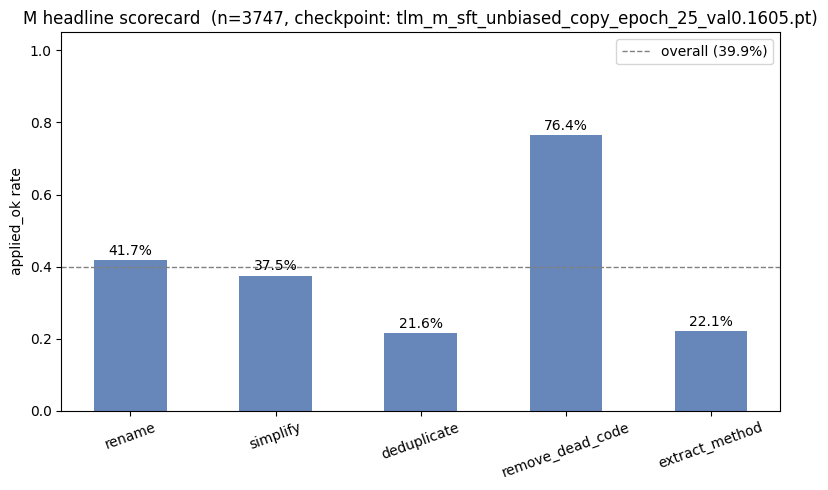

In [9]:
task_mean_scores = {}
for t in TASK_ORDER:
    if t not in results:
        continue
    task_mean_scores[t] = sum(results[t]["scores"]) / max(len(results[t]["scores"]), 1)
overall_score = sum(task_mean_scores.values()) / max(len(task_mean_scores), 1)

print(f"{'task':20s} {'mean_score':>10}  {'applied_ok%':>11}  {'n':>5}")
print("-" * 52)
for t in TASK_ORDER:
    if t not in results:
        continue
    r = results[t]
    ok_rate = r["ok"] / max(r["total"], 1)
    print(f"{t:20s} {task_mean_scores[t]:10.3f}  {ok_rate*100:10.1f}%  {r['total']:5d}")
print("-" * 52)
print(f"{'OVERALL_SCORE':20s} {overall_score:10.3f}  {total_ok/max(total_tot,1)*100:10.1f}%  {total_tot:5d}")

# -- ONE clean plot: applied_ok% per task, nothing else on this chart --
fig, ax = plt.subplots(figsize=(8, 5))
tasks_plot = [t for t in TASK_ORDER if t in results]
ok_rates = [results[t]["ok"] / max(results[t]["total"], 1) for t in tasks_plot]
bars = ax.bar(tasks_plot, ok_rates, color="#4C72B0", alpha=0.85, width=0.5)
for bar, val in zip(bars, ok_rates):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.015, f"{val:.1%}", ha="center", fontsize=10)
ax.axhline(total_ok/max(total_tot,1), color="gray", linestyle="--", linewidth=1,
           label=f"overall ({total_ok/max(total_tot,1):.1%})")
ax.set_ylim(0, 1.05); ax.set_ylabel("applied_ok rate")
ax.set_title(f"{MODEL_VARIANT} headline scorecard  (n={total_tot}, checkpoint: {CKPT_NAME})")
ax.tick_params(axis="x", rotation=20)
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "headline_scorecard.png", dpi=150, bbox_inches="tight")
plt.show()

## 7 -- Complexity Breakdown

Table only -- score falls off with task complexity; the table shows exactly
how much per task.

task                           bucket      n  mean_score
----------------------------------------------------------
rename                        3 sites      6       0.917
rename                       4+ sites    736       0.637
rename                            n/a      8       0.334
simplify                       1 hunk    631       0.587
simplify                      2 hunks     99       0.265
simplify                     3+ hunks     20       0.070
deduplicate                   2 hunks    153       0.448
deduplicate                  3+ hunks    562       0.449
deduplicate                       n/a     32       0.299
remove_dead_code               1 hunk    284       0.916
remove_dead_code              2 hunks    320       0.897
remove_dead_code             3+ hunks    146       0.737
extract_method                  short    327       0.348
extract_method                 medium    226       0.543
extract_method                   long    197       0.422


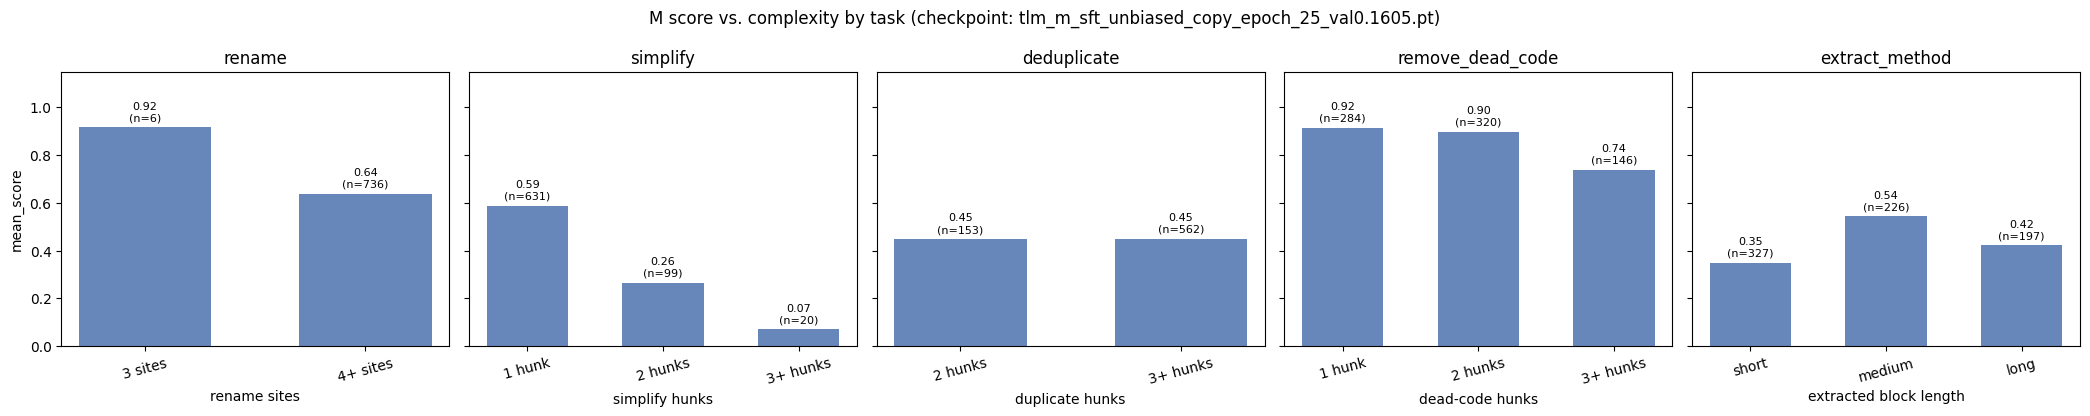

In [10]:
# Human-readable bucket labels instead of bare "1"/"2"/"3+"/"n/a" -- says what's
# actually being counted per task instead of making the reader infer it.
COMPLEXITY_AXIS_LABEL = {
    "rename": "rename sites",
    "remove_dead_code": "dead-code hunks",
    "simplify": "simplify hunks",
    "deduplicate": "duplicate hunks",
    "extract_method": "extracted block length",
}
COMPLEXITY_BUCKET_RENAME = {
    "rename":           {"1": "1 site", "2": "2 sites", "3": "3 sites", "4+": "4+ sites", "n/a": "n/a"},
    "remove_dead_code": {"1": "1 hunk", "2": "2 hunks", "3+": "3+ hunks", "n/a": "n/a"},
    "simplify":         {"1": "1 hunk", "2": "2 hunks", "3+": "3+ hunks", "n/a": "n/a"},
    "deduplicate":      {"1": "1 hunk", "2": "2 hunks", "3+": "3+ hunks", "n/a": "n/a"},
    "extract_method":   {"short": "short", "medium": "medium", "long": "long", "n/a": "n/a"},
}

def _grouped_scores_by_bucket(results_dict, ttype):
    r = results_dict.get(ttype)
    if not r:
        return {}
    bucket_fn, _ = COMPLEXITY_BUCKETS[ttype]
    all_vals = [c for c in r["complexities"] if c is not None]
    grouped = defaultdict(list)
    for score, cplx in zip(r["scores"], r["complexities"]):
        grouped[bucket_fn(cplx, all_vals)].append(score)
    return grouped


print(f"{'task':20s} {'bucket':>16}  {'n':>5}  {'mean_score':>10}")
print("-" * 58)
complexity_table = []
for ttype in TASK_ORDER:
    if ttype not in results:
        continue
    _, label_order = COMPLEXITY_BUCKETS[ttype]
    grouped = _grouped_scores_by_bucket(results, ttype)
    for l in label_order:
        if l not in grouped:
            continue
        m = sum(grouped[l]) / len(grouped[l])
        display_label = COMPLEXITY_BUCKET_RENAME[ttype].get(l, l)
        print(f"{ttype:20s} {display_label:>16}  {len(grouped[l]):>5}  {m:>10.3f}")
        complexity_table.append({"task": ttype, "bucket": l, "bucket_label": display_label,
                                  "n": len(grouped[l]), "mean_score": m})

# -- One bar chart per task, "n/a" dropped (it's a no-signal case, not a real
# complexity level) -- shows the same falls-off-with-complexity trend as the
# table, just easier to read at a glance for the thesis.
plot_tasks = [t for t in TASK_ORDER if t in results]
fig, axes = plt.subplots(1, len(plot_tasks), figsize=(4.2 * len(plot_tasks), 4.2), sharey=True)
if len(plot_tasks) == 1:
    axes = [axes]
for ax, ttype in zip(axes, plot_tasks):
    rows = [row for row in complexity_table if row["task"] == ttype and row["bucket"] != "n/a"]
    labels = [row["bucket_label"] for row in rows]
    means = [row["mean_score"] for row in rows]
    ns = [row["n"] for row in rows]
    bars = ax.bar(labels, means, color="#4C72B0", alpha=0.85, width=0.6)
    for bar, m, n in zip(bars, means, ns):
        ax.text(bar.get_x() + bar.get_width()/2, m + 0.02, f"{m:.2f}\n(n={n})",
                 ha="center", va="bottom", fontsize=8)
    ax.set_title(ttype); ax.set_xlabel(COMPLEXITY_AXIS_LABEL[ttype]); ax.set_ylim(0, 1.15)
    ax.tick_params(axis="x", rotation=15)
axes[0].set_ylabel("mean_score")
fig.suptitle(f"{MODEL_VARIANT} score vs. complexity by task (checkpoint: {CKPT_NAME})")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "complexity_breakdown.png", dpi=150, bbox_inches="tight")
plt.show()

## Latency Benchmark (wall-clock decode time)

Small held-out subsample, timed separately from the full eval above (does
not require re-running it) -- greedy-decode wall-clock latency per sample
and generated-tokens/sec, per task.

[rename] timed 18 samples (warmup 2 discarded)
[simplify] timed 18 samples (warmup 2 discarded)
[deduplicate] timed 18 samples (warmup 2 discarded)
[remove_dead_code] timed 18 samples (warmup 2 discarded)
[extract_method] timed 18 samples (warmup 2 discarded)

task                   mean_s   median_s    p95_s    tok/s    n
--------------------------------------------------------------
rename                  2.441      1.676    5.100     94.3   18
simplify                0.923      0.769    1.835    130.8   18
deduplicate             2.005      1.852    2.970    124.7   18
remove_dead_code        0.224      0.203    0.377    125.8   18
extract_method          0.881      0.728    1.757    129.5   18


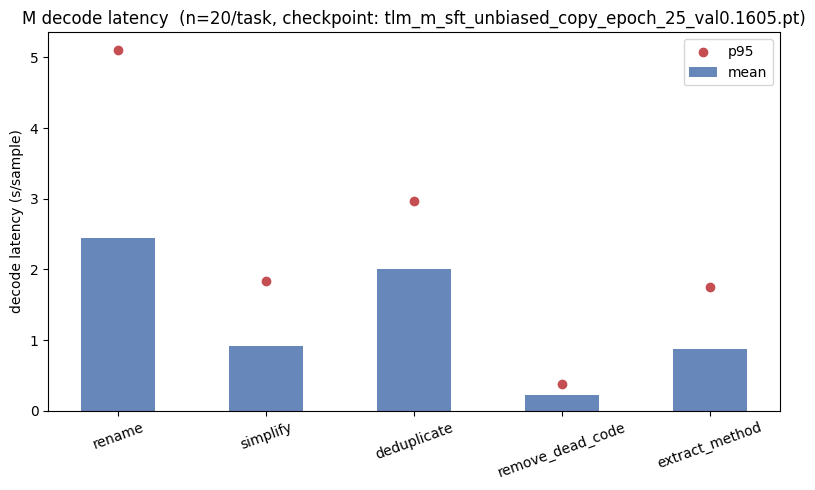

In [11]:
# -- Latency Benchmark: wall-clock decode time on a small held-out subsample --
# Separate from run_score_eval above -- does not touch its cache, no need to
# re-run the full 3750-record eval to get this.
LATENCY_N_PER_TASK = 20   # small timing subsample, not a re-run of the full eval
LATENCY_WARMUP = 2        # discard first N decodes per task (cold-start effects)

def _decode_timed(ttype, d):
    res = make_sft_sr(d, tokenizer, config)
    if res is None:
        return None
    enc_ids, _, task_id = res
    before_ids = tokenizer.encode(d["before"])

    if device.type == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    if ttype == "rename":
        out = decode_rename_without_collision(tlm_s, enc_ids, task_id, device, before_ids,
                                               tokenizer, config, max_retries=2, collect_conf=False)
    else:
        out = greedy_decode(tlm_s, enc_ids, task_id, device, collect_conf=False)
    if device.type == "cuda":
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - t0

    n_gen = len(out["tokens"])
    return {"latency_s": elapsed, "n_tokens": n_gen, "tokens_per_s": n_gen / elapsed if elapsed > 0 else 0.0}


latency_raw = {}
for ttype in TASK_ORDER:
    recs = by_type.get(ttype, [])
    if not recs:
        continue
    subsample = recs[:LATENCY_N_PER_TASK]
    per_sample = []
    for d in subsample:
        r = _decode_timed(ttype, d)
        if r is not None:
            per_sample.append(r)
    latency_raw[ttype] = per_sample[LATENCY_WARMUP:] if len(per_sample) > LATENCY_WARMUP else per_sample
    print(f"[{ttype}] timed {len(latency_raw[ttype])} samples "
          f"(warmup {min(LATENCY_WARMUP, len(per_sample))} discarded)")


def _pctl(vals, p):
    if not vals:
        return 0.0
    s = sorted(vals)
    k = (len(s) - 1) * p / 100
    f, c = int(k), min(int(k) + 1, len(s) - 1)
    return s[f] + (s[c] - s[f]) * (k - f)


latency_summary = {}
for ttype, samples in latency_raw.items():
    lat = [s["latency_s"] for s in samples]
    tps = [s["tokens_per_s"] for s in samples]
    latency_summary[ttype] = {
        "n": len(samples),
        "mean_latency_s": sum(lat) / max(len(lat), 1),
        "median_latency_s": _pctl(lat, 50),
        "p95_latency_s": _pctl(lat, 95),
        "mean_tokens_per_s": sum(tps) / max(len(tps), 1),
    }

print(f"\n{'task':20s} {'mean_s':>8} {'median_s':>10} {'p95_s':>8} {'tok/s':>8} {'n':>4}")
print("-" * 62)
for t in TASK_ORDER:
    if t not in latency_summary:
        continue
    r = latency_summary[t]
    print(f"{t:20s} {r['mean_latency_s']:8.3f} {r['median_latency_s']:10.3f} "
          f"{r['p95_latency_s']:8.3f} {r['mean_tokens_per_s']:8.1f} {r['n']:4d}")

fig, ax = plt.subplots(figsize=(8, 5))
tasks_plot = [t for t in TASK_ORDER if t in latency_summary]
means = [latency_summary[t]["mean_latency_s"] for t in tasks_plot]
p95s = [latency_summary[t]["p95_latency_s"] for t in tasks_plot]
x = range(len(tasks_plot))
ax.bar(x, means, color="#4C72B0", alpha=0.85, width=0.5, label="mean")
ax.scatter(x, p95s, color="#C44E52", zorder=3, label="p95")
ax.set_xticks(list(x)); ax.set_xticklabels(tasks_plot, rotation=20)
ax.set_ylabel("decode latency (s/sample)")
ax.set_title(f"{MODEL_VARIANT} decode latency  (n={LATENCY_N_PER_TASK}/task, checkpoint: {CKPT_NAME})")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "latency_benchmark.png", dpi=150, bbox_inches="tight")
plt.show()


## 8 -- Save for the Thesis

JSON (exact numbers) + Markdown (copy-pasteable table) + the scorecard PNG,
all under `OUTPUT_DIR`. Nothing here is re-computed.

In [12]:
summary = {
    "model_variant": MODEL_VARIANT,
    "run_name": RUN_NAME,
    "checkpoint": CKPT_NAME,
    "epoch": state["epoch"],
    "n_eval_records": total_tot,
    "headline_scorecard": {
        t: {"mean_score": task_mean_scores[t],
            "applied_ok_pct": results[t]["ok"] / max(results[t]["total"], 1) * 100,
            "n": results[t]["total"]}
        for t in TASK_ORDER if t in results
    },
    "overall_score": overall_score,
    "overall_applied_ok_pct": total_ok / max(total_tot, 1) * 100,
    "complexity_table": complexity_table,
    "latency_benchmark": latency_summary,
}

with open(OUTPUT_DIR / "score_eval_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

md_lines = [f"# {MODEL_VARIANT} Score Eval Summary\n",
            f"Checkpoint: `{CKPT_NAME}` (epoch {state['epoch']}) | n={total_tot}\n",
            "## Headline scorecard\n",
            "| task | mean_score | applied_ok% | n |",
            "|---|---|---|---|"]
for t in TASK_ORDER:
    if t not in results:
        continue
    r = summary["headline_scorecard"][t]
    md_lines.append(f"| {t} | {r['mean_score']:.3f} | {r['applied_ok_pct']:.1f}% | {r['n']} |")
md_lines.append(f"| **OVERALL** | **{overall_score:.3f}** | **{summary['overall_applied_ok_pct']:.1f}%** | {total_tot} |\n")
md_lines.append("## Complexity breakdown\n")
md_lines.append("| task | bucket | n | mean_score |")
md_lines.append("|---|---|---|---|")
for row in complexity_table:
    md_lines.append(f"| {row['task']} | {row['bucket']} | {row['n']} | {row['mean_score']:.3f} |")
md_lines.append("## Latency benchmark\n")
md_lines.append("| task | mean_s | median_s | p95_s | tok/s | n |")
md_lines.append("|---|---|---|---|---|---|")
for t in TASK_ORDER:
    if t not in latency_summary:
        continue
    r = latency_summary[t]
    md_lines.append(f"| {t} | {r['mean_latency_s']:.3f} | {r['median_latency_s']:.3f} | "
                     f"{r['p95_latency_s']:.3f} | {r['mean_tokens_per_s']:.1f} | {r['n']} |")
md_lines.append("\n## Figures\n")
for p in sorted(FIGURES_DIR.glob("*.png")):
    md_lines.append(f"![{p.stem}](figures/{p.name})")

with open(OUTPUT_DIR / "score_eval_summary.md", "w", encoding="utf-8") as f:
    f.write("\n".join(md_lines))

print("Saved:")
print(f"  {OUTPUT_DIR / 'score_eval_summary.json'}")
print(f"  {OUTPUT_DIR / 'score_eval_summary.md'}")
print(f"  {len(list(FIGURES_DIR.glob('*.png')))} figure(s) in {FIGURES_DIR}")

Saved:
  /content/drive/MyDrive/TLM_V03/data/checkpoints/tlm_m_sft_unbiased_copy/score_eval_outputs/score_eval_summary.json
  /content/drive/MyDrive/TLM_V03/data/checkpoints/tlm_m_sft_unbiased_copy/score_eval_outputs/score_eval_summary.md
  5 figure(s) in /content/drive/MyDrive/TLM_V03/data/checkpoints/tlm_m_sft_unbiased_copy/score_eval_outputs/figures
